In [106]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import utils as ut

from sklearn.datasets import fetch_openml

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Introduction

Here we have an Ising model simulation that has an external magnetic field applied which is derived from an MNIST image. The objective is to submit the structure factor heatmap to a logistic regression model and have it output the digit used.

This notebook allows one to choose the MNIST image submitted along with other parameters and to observe the resulting magnetic field, final spin configuration and its structure factor heatmap.

In [107]:
# PARAMETERS

i = 4 # the index of the MNIST image to be used
T = 2.5 # chosen dimensionless temperature, T = k_B T / J
alpha_over_J = 1.0 # hyperparameter defining how strong the extremes of the B-field are

sweeps = 10000 # number of monte carlo sweeps

n_samples = 100 # how many samples of structure factor to measure
sample_interval = 10  # how many sweeps between measurements of structure factor

In [108]:
# retrieve MNIST dataset via OpenML
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
y = y.astype(int)

# normalise to values between 0 and 1
X = X.astype(np.float64) / 255.0

# View external magnetic field derived from MNIST image

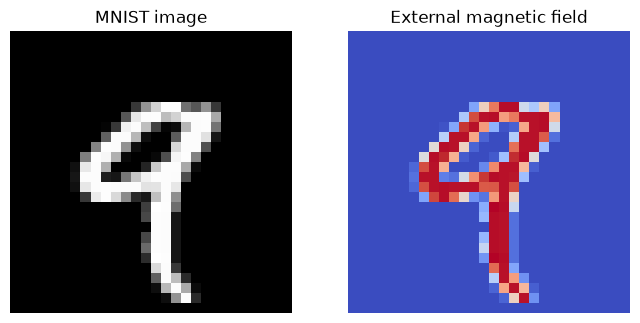

In [109]:
image = X[i].reshape(28, 28)
H = ut.image_to_magnetic_field(image, alpha_over_J)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("MNIST image")

axes[1].imshow(H, cmap="coolwarm", vmin=-alpha_over_J, vmax=alpha_over_J)
axes[1].set_title("External magnetic field")

for ax in axes:
    ax.axis("off")

plt.show()

# View final spin configuration

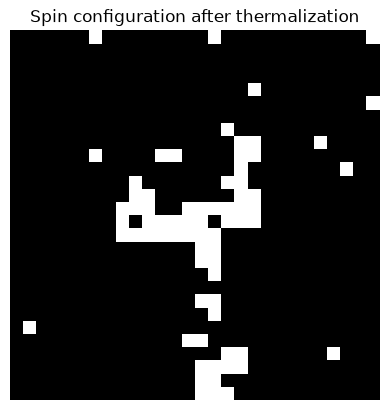

In [110]:
L = 28
lattice = ut.generate_lattice(L)

lattice = ut.metropolis(lattice, sweeps, T, H)

plt.imshow(lattice, cmap="gray", vmin=-1, vmax=1)
plt.title("Spin configuration after thermalization")
plt.axis("off")
plt.show()

# Compute and view average structure factor

This computation is done on the same lattice that was sent to equilibrium by the previous code block.

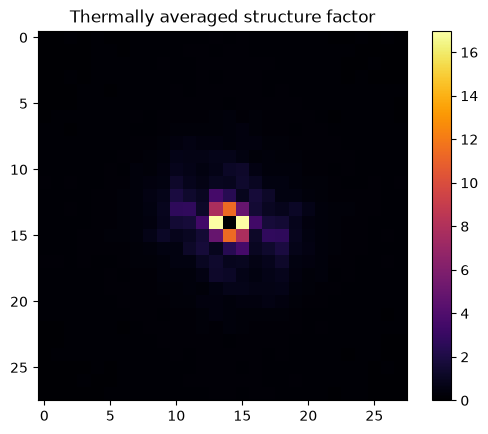

In [111]:
S_avg = np.zeros((28, 28))

for i in range(n_samples):
    lattice = ut.metropolis(lattice, sample_interval, T, H)
    S_avg += ut.structure_factor(lattice)

S_avg /= n_samples

# plot average structure factor
plt.imshow(S_avg, cmap="inferno")
plt.title("Thermally averaged structure factor")
plt.colorbar()
plt.show()